# Model-independent and reconstruction-free evidence for cosmic acceleration from DESI baryon acoustic oscillations

This notebook reproduces all figures and tables.

Conventions: $S_F$, $S_V$, $S_{VH}$ are defined so that $S>0$ is evidence for acceleration; the statistics are defined such that they are linear in DESI's measured $F_{AP}$, $D_V/r_d$ and $D_H/r_d$, which are used directly (no $r_d$ or $H_0$ needed). $Z_{\max}$ and $Z_{\rm avg}$ use the first $m=3$ tracers as default ($z\le0.934$).

In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid
from scipy.stats import norm, multivariate_normal
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
np.set_printoptions(precision=4, suppress=True)
%config InlineBackend.figure_format = 'retina'

In [2]:
# Parameters
m_zmax   = 3        # only consider the first 3 redshift bins to search for acceleration
N_MOCKS  = int(1e7)
rng_seed = 0

# Mocks
LABELS = { "coasting": "coasting ($q=0$)", "w0wacdm": r"$w_0w_a$CDM", "desi_lcdm": r"$\Lambda$CDM"}
COLORS = {"coasting": "#e0a030", "w0wacdm": "#67b6f3", "desi_lcdm": "dimgray"}
ZGRID = np.linspace(0.0, 2.5, 20000)

# Plot settings
fontsize = 18
markersize = 2
cm_rc = {
    "font.size": fontsize,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.formatter.use_mathtext": True,
}
label_real = "DESI DR2 BAO"
color_real = "#22201d" 
sigma_formatter = FuncFormatter(lambda x, _: "$0$" if x == 0 else rf"${x:g}\sigma$")  # Z-score ticks: 0, 2σ, ...
sigma_ticksize = 14  
stat_style = {"Z_F":  dict(ls=":",  lw=2.0, marker="^", label=r"$S_F$ ($F_\mathrm{AP}$)"),
              "Z_V":  dict(ls="--", lw=2.0, marker="s", label=r"$S_V$ ($D_V$)"),
              "Z_VH": dict(ls="-",  lw=2.5, marker="o", label=r"$S_{VH}$ ($D_V/D_H$)")}

# Constants
C_KM_S = 299792.458  # km/s

## Data from DESI DR2

Taken from Table IV of Abdul Karim et al. 2025 (arXiv:2503.14738)

In [3]:
# Tracers & redshifts
TRACERS = ["LRG1", "LRG2", "LRG3+ELG1", "ELG2", "QSO", "Lya"]
Z = np.array([0.510, 0.706, 0.934, 1.321, 1.484, 2.330])

# D_M/r_d
DM = np.array([13.588, 17.351, 21.576, 27.601, 30.512, 38.988]) 
DM_ERR = np.array([0.167, 0.177, 0.152, 0.318, 0.760, 0.531])

# D_H/r_d
DH = np.array([21.863, 19.455, 17.641, 14.176, 12.817, 8.632])        
DH_ERR = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])

# F_AP = D_M/D_H
FAP = np.array([0.622, 0.892, 1.223, 1.948, 2.386, 4.518])          
FAP_ERR = np.array([0.017, 0.021, 0.019, 0.045, 0.136, 0.097])

# D_V/r_d
DV = np.array([12.720, 16.050, 19.721, 24.252, 26.055, 31.267])
DV_ERR = np.array([0.099, 0.110, 0.091, 0.174, 0.398, 0.256])

# D_V/r_d BGS data
Z_BGS = 0.295
DV_BGS = 7.942
DV_BGS_ERR = 0.075

## Define functions and reference cosmologies

$E(z)=(1+z)e^{Q(z)}$ with $Q(z)=\int_0^z q(z')/(1+z')\,dz'$. 

Reference cosmologies:

- **Coasting**, $q(z)\equiv0 \Rightarrow E(z)=1+z$.
- **DESI DR2 flat $\Lambda$CDM**: $\Omega_m=0.2975$ (DESI DR2 BAO-alone fit, arXiv:2503.14738 Eq. 17).
- **DESI+CMB flat $w_0w_a$CDM**: $\Omega_m=0.353$, $w_0=-0.42$, $w_a=-1.75$ with:

$$E_\mathrm{CPL}(z)^2 = \Omega_m(1+z)^3 + (1-\Omega_m)(1+z)^{3(1+w_0+w_a)} \exp(-3 w_a z/(1+z))$$

We only take above values from the papers and analytically fit the overall amplitude $Y$ to the real $D_H/r_d$ BAO data.
$S_F$ is amplitude-free; $S_V$ and $S_{VH}$ are linear in $D/r_d$, so their truth-level values scale with $Y$
(their significance on real data does not depend on it).


In [4]:
def E_coasting(z):
    return 1.0 + np.asarray(z, dtype=float)

def E_cpl(z, om, w0, wa):
    z = np.asarray(z, dtype=float)
    return np.sqrt(om * (1 + z) ** 3 + (1 - om) * (1 + z) ** (3 * (1 + w0 + wa)) * np.exp(-3 * wa * z / (1 + z)))

def theory_curves(E_fn, Y):
    '''Y = H0 r_d [km/s]. Returns dm(z), dh(z), dv(z), fap(z) callables;
    dm/dh/dv are already in DESI's r_d-normalized units (i.e. dm(z) = D_M(z)/r_d)'''
    Eg = E_fn(ZGRID)
    dm_grid = (C_KM_S / Y) * cumulative_trapezoid(1.0 / Eg, ZGRID, initial=0.0)
    dh_grid = (C_KM_S / Y) / Eg
    dv_grid = (ZGRID * dm_grid ** 2 * dh_grid) ** (1.0 / 3.0)

    dm = lambda z: np.interp(z, ZGRID, dm_grid)
    dh = lambda z: np.interp(z, ZGRID, dh_grid)
    dv = lambda z: np.interp(z, ZGRID, dv_grid)
    fap = lambda z: dm(z) / dh(z)  # Y-independent
    return dm, dh, dv, fap

def fit_amplitude_dh(E_fn):
    '''Closed-form fit of Y=H0 r_d to the real DESI D_H/r_d data (6 tracers, no BGS) 
    for a fixed shape E_fn: D_H/r_d = x(z)/Y with x(z)=c/E(z), 
    by setting \partial \chi^2 / \partial Y == 0.'''
    x = C_KM_S / E_fn(Z)
    A_hat = np.sum(x * DH / DH_ERR ** 2) / np.sum(x ** 2 / DH_ERR ** 2)  # A = 1/Y
    return 1.0 / A_hat

# Only shape is assumed for all (i.e. Omega_m, w0, wa), H0*rd is fit from BAO data, even for LCDM, w0wa. 
TRUTHS = {
    "coasting": (E_coasting, None),
    "desi_lcdm": (lambda z: E_cpl(z, 0.2975, -1.0, 0.0), None),
    "w0wacdm": (lambda z: E_cpl(z, 0.353, -0.42, -1.75), None),
    }

TRUTHS = {name: (E_fn, fit_amplitude_dh(E_fn)) for name, (E_fn, _) in TRUTHS.items()}
pd.DataFrame({"H0*r_d [km/s]": {t: f"{y:.1f}" for t, (_, y) in TRUTHS.items()},
              "r_d*H0/100 [Mpc-equiv]": {t: f"{y/100:.2f}" for t, (_, y) in TRUTHS.items()}})

,H0*r_d [km/s],r_d*H0/100 [Mpc-equiv]
coasting,9414.1,94.14
desi_lcdm,10178.4,101.78
w0wacdm,9402.0,94.02


## Define $S_F$, $S_V$ statistics

- $S_F(z)\equiv(1+z)\ln(1+z)-F_{AP}(z)$.

- $S_V(z)\equiv g(z_{\rm ref})D_V(z)-g(z)D_V(z_{\rm ref})$, $g(z)=[z\ln^2(1+z)/(1+z)]^{1/3}$, $z_{\rm ref}=0.295$ (BGS).

- $S_{VH}(z)\equiv(1+z)g(z_{\rm ref})D_H(z)-D_V(z_{\rm ref})$ from Sutherland (2012, arXiv:1105.3838).

All three are linear in DESI's quoted $F_{AP}$, $D_V/r_d$ and $D_H/r_d$, so they are exactly Gaussian.

$q \geq 0$ on $[0,z]$ $\implies$ $S(z) \leq 0$.

In [5]:
def g_coasting(z):
    z = np.asarray(z, dtype=float)
    return (z * np.log1p(z) ** 2 / (1.0 + z)) ** (1.0 / 3.0)

def S_F(fap, z):
    z = np.asarray(z, dtype=float)
    return (1.0 + z) * np.log1p(z) - np.asarray(fap, dtype=float)

def S_V(dv, dv_ref, z, z_ref):
    return g_coasting(z_ref) * np.asarray(dv, dtype=float) - g_coasting(z) * np.asarray(dv_ref, dtype=float)

def S_VH(dh, dv_ref, z, z_ref):
    z = np.asarray(z, dtype=float)
    return (1.0 + z) * g_coasting(z_ref) * np.asarray(dh, dtype=float) - np.asarray(dv_ref, dtype=float)

### Compute covariances from real DESI data

The statistics are linear in DESI's quoted numbers, so $\sigma_{\rm self}$ and the covariances depend only on the quoted errors.

In [6]:
# S_F
sigma_SF_real = FAP_ERR

# S_V shares the BGS anchor across tracers: diagonal plus rank one.
_g = g_coasting(Z)
SIGMA_SV_COV = np.diag((g_coasting(Z_BGS) * DV_ERR) ** 2) + DV_BGS_ERR ** 2 * np.outer(_g, _g)
sigma_SV_real = np.sqrt(np.diag(SIGMA_SV_COV))

# S_VH shares the same anchor, with coefficient -1 at every tracer.
_c = (1.0 + Z) * g_coasting(Z_BGS)
SIGMA_VH_COV = np.diag((_c * DH_ERR) ** 2) + DV_BGS_ERR ** 2 * np.ones((len(Z), len(Z)))
sigma_SVH_real = np.sqrt(np.diag(SIGMA_VH_COV))

### Define $Z_\mathrm{max}$ and $Z_\mathrm{avg}$

- $Z_\mathrm{max} = \mathrm{max}_{i \le m} Z_i$ with $Z_i = \frac{S(z_i)}{\sigma_S(z_i)}$
- $Z_\mathrm{avg} = \frac{\bar S_m}{\sigma_{\bar S}}$ with  $\bar S_m = \frac{1}{m}\sum_{i=1}^{m} S(z_i)$

In [7]:
def Zmax(Z_stat, m):
    Zmax = Z_stat[0:m].max()
    return Zmax

def Zmax_mocks(Z_stat, m):
    Zmax = np.array(Z_stat[:, 0:m].max(axis=1))
    return Zmax

def Zavg(S, sigma_stat, sigma_stat_cov, m):
    if sigma_stat_cov is None:
        sigma_avg = float(np.sqrt(np.sum(sigma_stat[0:m] ** 2))) / m
    else:
        sigma_avg = float(np.sqrt(sigma_stat_cov[:m, :m].sum())) / m
    Zavg = float(S[0:m].mean() / sigma_avg)  # = mean(S)/sigma_self_avg
    return Zavg

def Zavg_mocks(S, sigma_stat, sigma_stat_cov, m):
    if sigma_stat_cov is None:
        sigma_avg = float(np.sqrt(np.sum(sigma_stat[0:m] ** 2))) / m
    else:
        sigma_avg = float(np.sqrt(sigma_stat_cov[:m, :m].sum())) / m
    Zavg = np.array(S[:, 0:m].mean(axis=1) / sigma_avg)  # = mean(S)/sigma_self_avg
    return Zavg

## Generate mocks
Draw DESI's quoted marginals $F_{AP}$, $D_V/r_d$, $D_H/r_d$ (and $D_V/r_d$ at BGS) as independent Gaussians.
Each statistic uses one quoted quantity per tracer, so the within-tracer correlations do not enter.
Compute $S_F$, $S_V$, $S_{VH}$ for truth and for each mock. 

In [8]:
def run_mocks(name, n_mocks, seed):
    '''Generate n_mocks mocks for one truth'''
    E_fn, Y = TRUTHS[name]
    dm_fn, dh_fn, dv_fn, fap_fn = theory_curves(E_fn, Y)

    dm_true, dh_true = dm_fn(Z), dh_fn(Z)
    dv_ref_true = dv_fn(Z_BGS)
    S_F_true = S_F(fap_fn(Z), Z)
    S_V_true = S_V(dv_fn(Z), dv_ref_true, Z, Z_BGS)
    S_VH_true = S_VH(dh_true, dv_ref_true, Z, Z_BGS)

    Z_F_true = S_F_true / sigma_SF_real
    Z_V_true = S_V_true / sigma_SV_real
    Z_VH_true = S_VH_true / sigma_SVH_real

    Z_F_max_true = Zmax(Z_F_true, m_zmax)
    Z_F_avg_true = Zavg(S_F_true, sigma_SF_real, None, m_zmax)
    Z_V_max_true = Zmax(Z_V_true, m_zmax)
    Z_V_avg_true = Zavg(S_V_true, sigma_SV_real, SIGMA_SV_COV, m_zmax)
    Z_VH_max_true = Zmax(Z_VH_true, m_zmax)
    Z_VH_avg_true = Zavg(S_VH_true, sigma_SVH_real, SIGMA_VH_COV, m_zmax)

    rng = np.random.default_rng(seed)
    nt = len(Z)
    fap_mock = fap_fn(Z)[None, :] + rng.normal(0.0, FAP_ERR, size=(n_mocks, nt))
    dv_mock = dv_fn(Z)[None, :] + rng.normal(0.0, DV_ERR, size=(n_mocks, nt))
    dh_mock = dh_true[None, :] + rng.normal(0.0, DH_ERR, size=(n_mocks, nt))
    dv_ref_mock = dv_ref_true + rng.normal(0.0, DV_BGS_ERR, size=n_mocks)

    S_F_mock = S_F(fap_mock, Z[None, :])
    S_V_mock = S_V(dv_mock, dv_ref_mock[:, None], Z[None, :], Z_BGS)
    S_VH_mock = S_VH(dh_mock, dv_ref_mock[:, None], Z[None, :], Z_BGS)

    Z_F_mock = S_F_mock / sigma_SF_real
    Z_V_mock = S_V_mock / sigma_SV_real
    Z_VH_mock = S_VH_mock / sigma_SVH_real

    Z_F_max_mock = Zmax_mocks(Z_F_mock, m_zmax)
    Z_F_avg_mock = Zavg_mocks(S_F_mock, sigma_SF_real, None, m_zmax)
    Z_V_max_mock = Zmax_mocks(Z_V_mock, m_zmax)
    Z_V_avg_mock = Zavg_mocks(S_V_mock, sigma_SV_real, SIGMA_SV_COV, m_zmax)
    Z_VH_max_mock = Zmax_mocks(Z_VH_mock, m_zmax)
    Z_VH_avg_mock = Zavg_mocks(S_VH_mock, sigma_SVH_real, SIGMA_VH_COV, m_zmax)

    return dict(
                fap_fn=fap_fn, 
                dv_fn=dv_fn, 
                dh_fn=dh_fn, 
                S_F_true=S_F_true, 
                S_V_true=S_V_true, 
                S_VH_true=S_VH_true, 
                Z_F_true = Z_F_true,
                Z_V_true = Z_V_true,
                Z_VH_true = Z_VH_true,
                Z_F_max_true = Z_F_max_true,
                Z_F_avg_true = Z_F_avg_true,
                Z_V_max_true = Z_V_max_true,
                Z_V_avg_true = Z_V_avg_true,
                Z_VH_max_true = Z_VH_max_true,
                Z_VH_avg_true = Z_VH_avg_true,
                fap_mock=fap_mock, 
                dv_mock=dv_mock,
                dh_mock=dh_mock,
                dv_ref_mock=dv_ref_mock,
                S_F_mock=S_F_mock, 
                S_V_mock=S_V_mock,
                S_VH_mock=S_VH_mock,
                Z_F_mock = Z_F_mock,
                Z_V_mock = Z_V_mock,
                Z_VH_mock = Z_VH_mock,
                Z_F_max_mock = Z_F_max_mock,
                Z_F_avg_mock = Z_F_avg_mock,
                Z_V_max_mock = Z_V_max_mock,
                Z_V_avg_mock = Z_V_avg_mock,
                Z_VH_max_mock = Z_VH_max_mock,
                Z_VH_avg_mock = Z_VH_avg_mock,
               )

mocks = {t: run_mocks(t, N_MOCKS, seed=i) for i, t in enumerate(TRUTHS)}


# Fig. 1
Expansion speed 
$$\dot{a} = H/(1+z)$$ 
normalised to the BGS "effective coasting speed" 
$$\dot{a}_\mathrm{eff}(z_\mathrm{ref}) = g(z_\mathrm{ref})/D_V(z_\mathrm{ref})$$
Bands are the 68% range of the mocks.

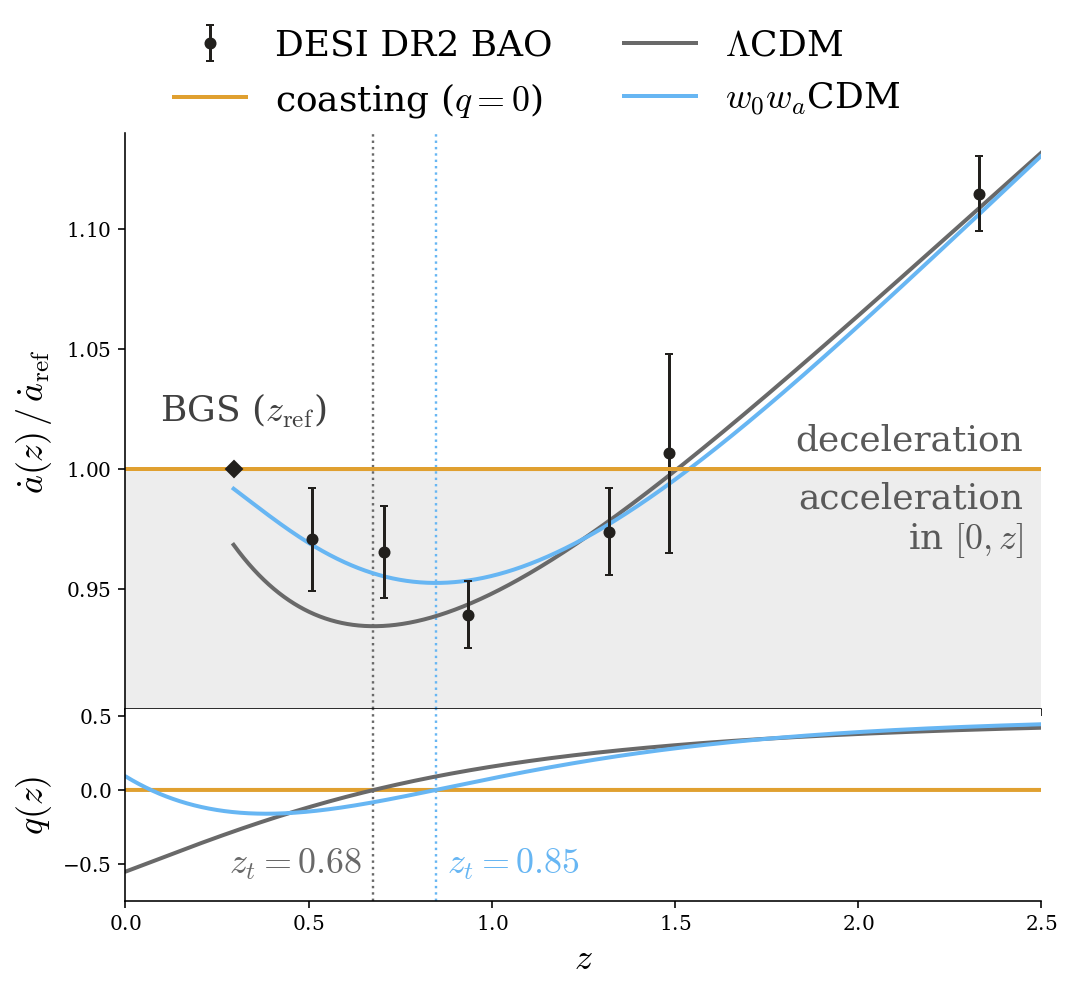

In [9]:
with plt.rc_context(cm_rc):
    fig, (ax, axq) = plt.subplots(2, 1, figsize=(7.5, 7.), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

    # mocks
    zfine = np.linspace(1e-4, 2.5, 2000)
    zfine_vh = zfine[zfine >= Z_BGS]
    c_VH = (1.0 + Z) * g_coasting(Z_BGS)
    for t in TRUTHS:
        dv_ref = mocks[t]["dv_fn"](Z_BGS)
        ax.plot(zfine_vh, dv_ref / ((1.0 + zfine_vh) * g_coasting(Z_BGS) * mocks[t]["dh_fn"](zfine_vh)), color=COLORS[t], lw=2, label=LABELS[t])
    # real
    y_VH_real = DV_BGS / (c_VH * DH)
    yerr_VH_real = sigma_SVH_real / (c_VH * DH)
    ax.errorbar(Z, y_VH_real, yerr=yerr_VH_real, marker="o", ms=5, ls="", color=color_real, lw=1.5, capsize=2, label=label_real)
    ax.errorbar([Z_BGS], [1.0], marker="D", ms=6, ls="", color=color_real, capsize=2)
    ax.annotate(r"BGS ($z_\mathrm{ref}$)", (Z_BGS, 1.0), xytext=(0.32, 1.02), ha="center", fontsize=fontsize, color="0.25")

    # acceleration side of the coasting boundary
    ax.axhspan(0.0, 1.0, color="0.93", zorder=0)
    ax.axhline(1.0, color=COLORS["coasting"], lw=2)
    ax.text(2.45, 0.995, "acceleration\nin $[0,z]$", ha="right", va="top", fontsize=fontsize, color="0.35")
    ax.text(2.45, 1.005, "deceleration", ha="right", va="bottom", fontsize=fontsize, color="0.35")

    ax.set_ylabel(r"$\dot a(z)\,/\,\dot a_{\rm ref}$", fontsize=fontsize)
    ax.set_ylim(0.90, 1.14)
    ax.set_xlim(0.0, 2.5)
    ax.set_yticks([0.95, 1.0, 1.05, 1.1])

    # bottom: q(z) of the truths with transition redshifts (as Fig. 1)
    for t, (E_fn, _) in TRUTHS.items():
        q = np.gradient(np.log(E_fn(zfine) / (1.0 + zfine)), np.log1p(zfine))
        axq.plot(zfine, q, color=COLORS[t], lw=2)
        if t == "coasting":
            continue
        zt = zfine[np.flatnonzero(np.diff(np.sign(q)) > 0)[-1]]  # w0wa also re-decelerates at z~0.07; take the higher crossing
        for a in (ax, axq):
            a.axvline(zt, color=COLORS[t], lw=1.2, ls=":", zorder=0)
        # LCDM label left of its line, w0wa right of its line
        lcdm = t == "desi_lcdm"
        axq.text(zt - 0.03 if lcdm else zt + 0.03, -0.5, rf"$z_t={zt:.2f}$", fontsize=fontsize, color=COLORS[t], ha="right" if lcdm else "left", va="center")
    axq.set_ylabel(r"$q(z)$", fontsize=fontsize)
    axq.set_ylim(-0.75, 0.55)
    axq.set_xlabel(r"$z$", fontsize=fontsize)

    fig.align_ylabels([ax, axq])
    for a in (ax, axq):
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    order = [labels.index(k) for k in (label_real, LABELS["coasting"], LABELS["desi_lcdm"], LABELS["w0wacdm"])]
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.88))
    fig.subplots_adjust(hspace=0.0)
    fig.legend([handles[k] for k in order], [labels[k] for k in order], loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=2, frameon=False, fontsize=fontsize)

plt.savefig("Fig1.pdf", format="PDF", bbox_inches="tight")


## Compute $S_F$, $S_V$ from real DESI DR2 data


In [10]:
S_F_real = S_F(FAP, Z)
S_V_real = S_V(DV, DV_BGS, Z, Z_BGS)
S_VH_real = S_VH(DH, DV_BGS, Z, Z_BGS)


## Fig. 2: $F_\mathrm{AP}$, $S_F$, $D_V$, $S_V$

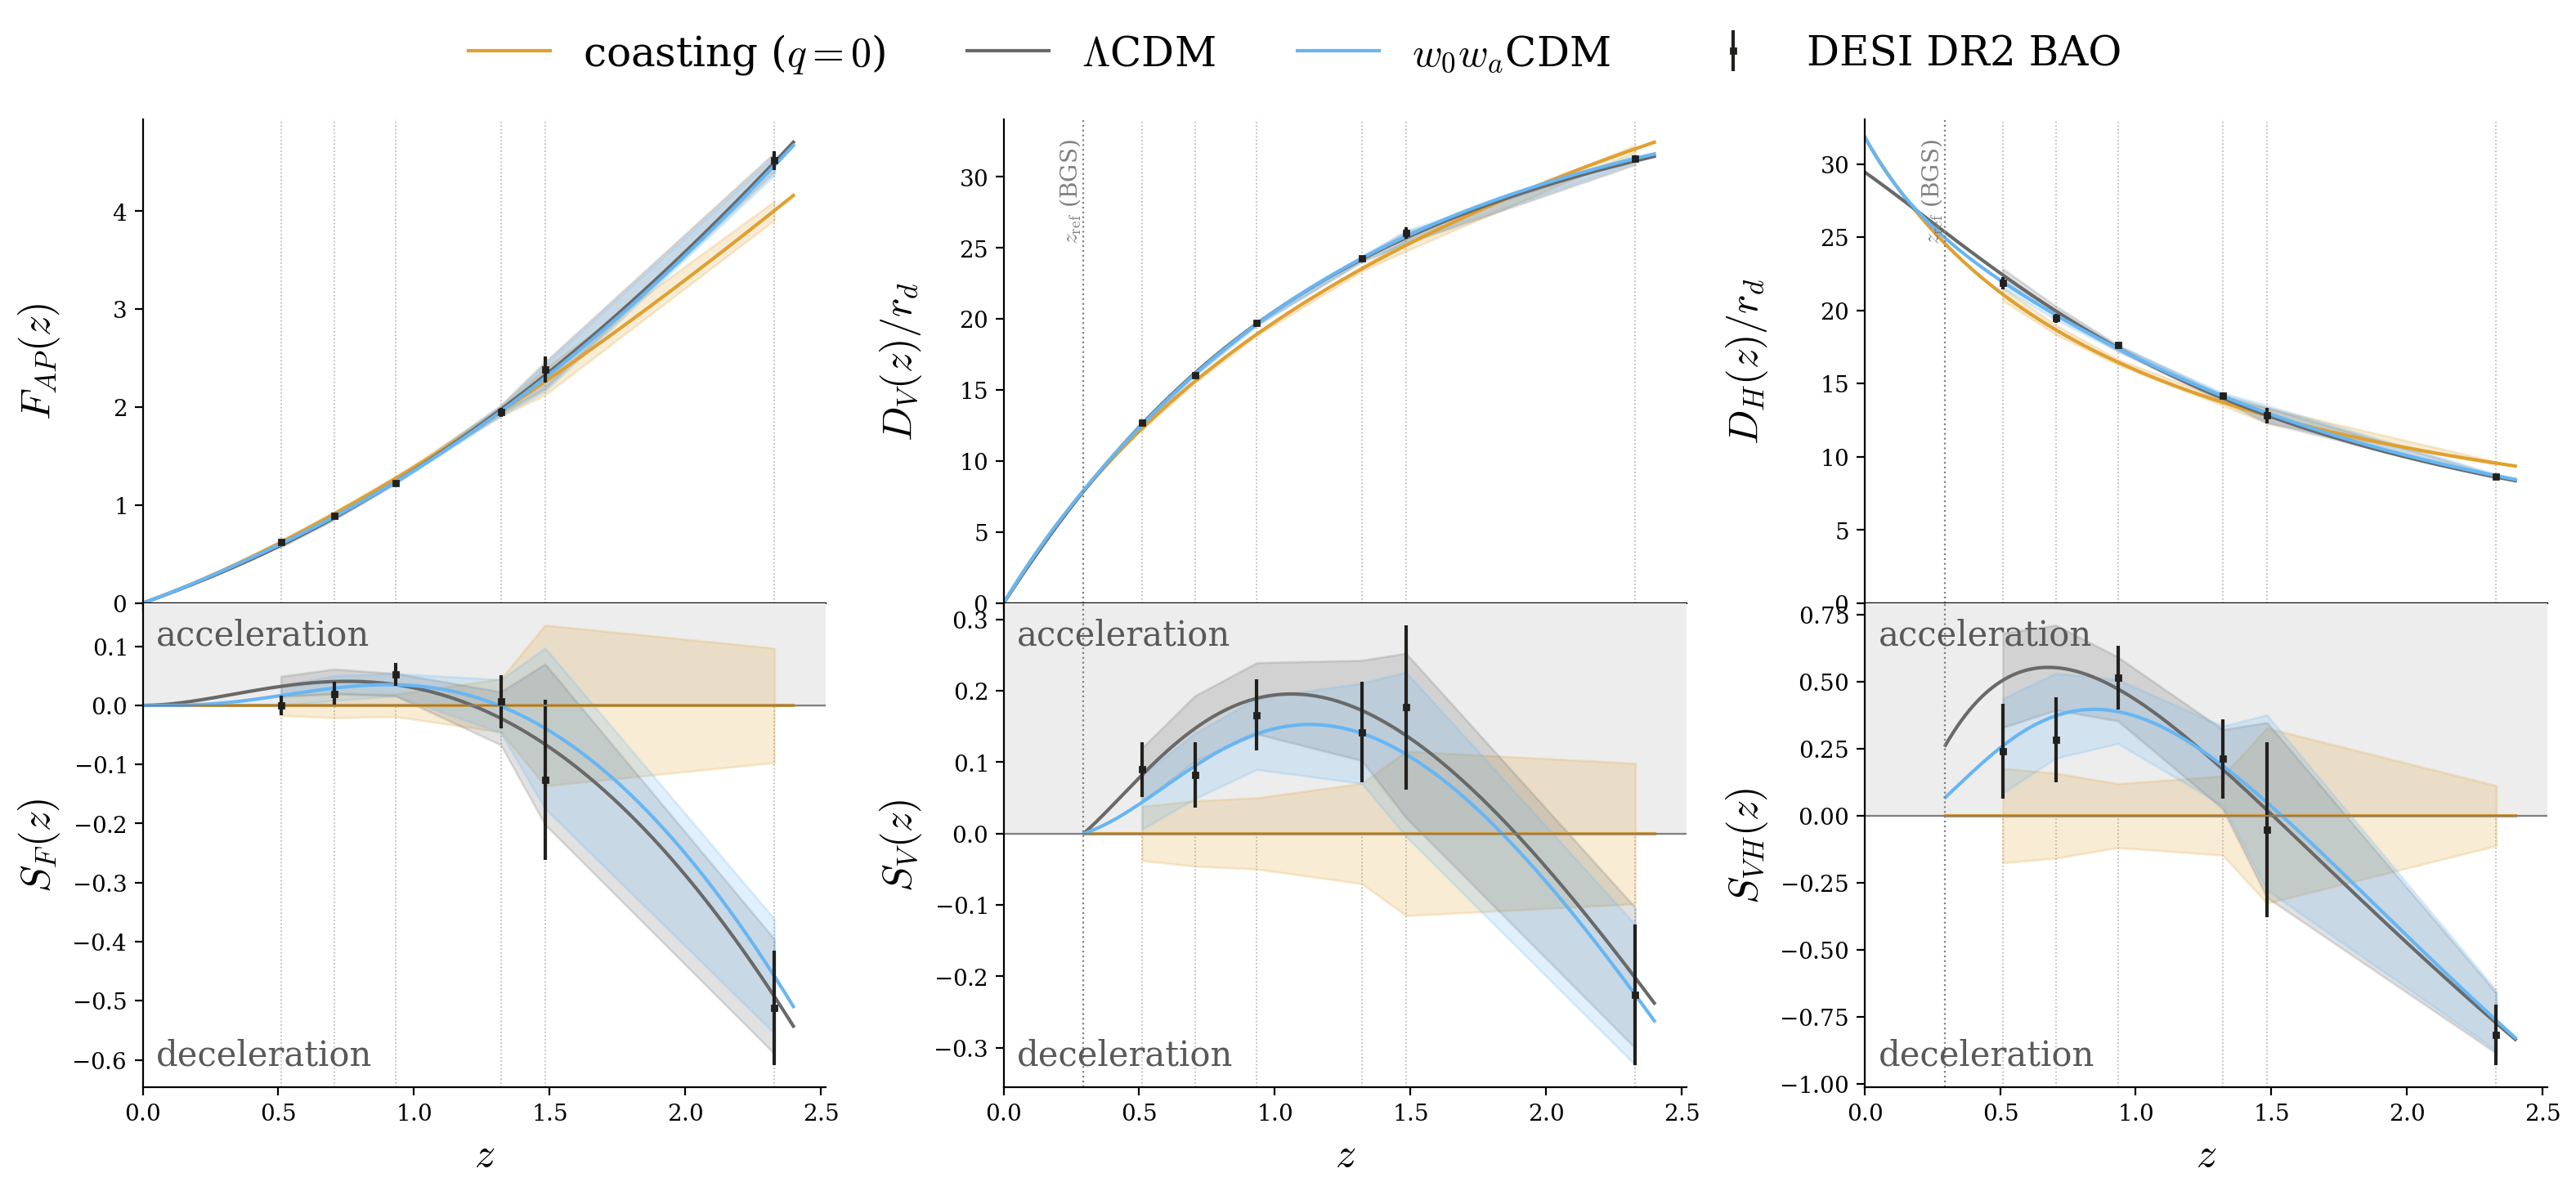

In [11]:
lw = 1.5
with plt.rc_context(cm_rc):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex="col", gridspec_kw={"height_ratios": [1, 1]})
    zfine = np.linspace(1e-4, 2.4, 500)

    def mark_tracers(ax):
        for z in Z:ax.axvline(z, color="grey", lw=0.6, ls=":", alpha=0.6, zorder=0)

    # F_AP
    ax = axes[0, 0]
    for t in TRUTHS:
        # mocks
        ax.plot(zfine, mocks[t]["fap_fn"](zfine), color=COLORS[t], label=LABELS[t])
        lo, hi = np.percentile(mocks[t]["fap_mock"], [15.87, 84.13], axis=0)
        ax.fill_between(Z, lo, hi, color=COLORS[t], alpha=0.2) 
    # real
    ax.errorbar(Z, FAP, yerr=FAP_ERR, marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
    # aesthetics
    mark_tracers(ax)
    ax.set_ylabel(r"$F_{AP}(z)$", fontsize=fontsize)
    ax.set_ylim(0)
    ax.set_xlim(0)
    ax.tick_params(labelbottom=False)

    # D_V
    ax = axes[0, 1]
    for t in TRUTHS:
        # mocks
        ax.plot(zfine, mocks[t]["dv_fn"](zfine), color=COLORS[t])
        lo, hi = np.percentile(mocks[t]["dv_mock"], [15.87, 84.13], axis=0)
        ax.fill_between(Z, lo, hi, color=COLORS[t], alpha=0.2)
    # real
    ax.errorbar(Z, DV, yerr=DV_ERR, marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
    # aesthetics
    mark_tracers(ax)
    ax.axvline(Z_BGS, color="grey", lw=0.8, ls=":")
    trans = ax.get_xaxis_transform()  # x in data coords, y in axes fraction
    ax.text(Z_BGS, 0.96, r"$z_{\rm ref}$ (BGS)", rotation=90, va="top", ha="right", fontsize=10, color="grey", transform=trans)
    ax.set_ylabel(r"$D_V(z)/r_d$", fontsize=fontsize)
    ax.set_ylim(0)
    ax.set_xlim(0)
    ax.tick_params(labelbottom=False)

    # D_H (for S_VH)
    ax = axes[0, 2]
    for t in TRUTHS:
        # mocks
        ax.plot(zfine, mocks[t]["dh_fn"](zfine), color=COLORS[t])
        lo, hi = np.percentile(mocks[t]["dh_mock"], [15.87, 84.13], axis=0)
        ax.fill_between(Z, lo, hi, color=COLORS[t], alpha=0.2)
    # real
    ax.errorbar(Z, DH, yerr=DH_ERR, marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
    # aesthetics
    mark_tracers(ax)
    ax.axvline(Z_BGS, color="grey", lw=0.8, ls=":")
    trans = ax.get_xaxis_transform()
    ax.text(Z_BGS, 0.96, r"$z_{\rm ref}$ (BGS)", rotation=90, va="top", ha="right", fontsize=10, color="grey", transform=trans)
    ax.set_ylabel(r"$D_H(z)/r_d$", fontsize=fontsize)
    ax.set_ylim(0)
    ax.set_xlim(0)
    ax.tick_params(labelbottom=False)

    # S_F
    ax = axes[1, 0]
    for t in TRUTHS:
        # mocks
        ax.plot(zfine, S_F(mocks[t]["fap_fn"](zfine), zfine), color=COLORS[t])
        lo, hi = np.percentile(mocks[t]["S_F_mock"], [15.87, 84.13], axis=0)
        ax.fill_between(Z, lo, hi, color=COLORS[t], alpha=0.2) 
    # real
    ax.errorbar(Z, S_F_real, sigma_SF_real, marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
    # aesthetics
    mark_tracers(ax)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylabel(r"$S_F(z)$", fontsize=fontsize)
    ax.set_xlabel("$z$", fontsize=fontsize)

    # S_V
    ax = axes[1, 1]
    zfine_sv = zfine[zfine >= Z_BGS]  # no model lines below z_ref for S_V
    for t in TRUTHS:
        # mocks
        dv_ref = mocks[t]["dv_fn"](Z_BGS)
        ax.plot(zfine_sv, S_V(mocks[t]["dv_fn"](zfine_sv), dv_ref, zfine_sv, Z_BGS), color=COLORS[t])
        lo, hi = np.percentile(mocks[t]["S_V_mock"], [15.87, 84.13], axis=0)
        ax.fill_between(Z, lo, hi, color=COLORS[t], alpha=0.2)  # linear interpolation between tracers
    # real
    ax.errorbar(Z, S_V_real, sigma_SV_real, marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
    # aesthetics
    mark_tracers(ax)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(Z_BGS, color="grey", lw=0.8, ls=":")
    ax.set_ylabel(r"$S_V(z)$", fontsize=fontsize)
    ax.set_xlabel("$z$", fontsize=fontsize)

    # S_VH (Sutherland speed-trap)
    ax = axes[1, 2]
    zfine_vh = zfine[zfine >= Z_BGS]  # no model lines below z_ref for S_VH
    for t in TRUTHS:
        # mocks
        dv_ref = mocks[t]["dv_fn"](Z_BGS)
        ax.plot(zfine_vh, S_VH(mocks[t]["dh_fn"](zfine_vh), dv_ref, zfine_vh, Z_BGS), color=COLORS[t])
        lo, hi = np.percentile(mocks[t]["S_VH_mock"], [15.87, 84.13], axis=0)
        ax.fill_between(Z, lo, hi, color=COLORS[t], alpha=0.2)  # linear interpolation between tracers
    # real
    ax.errorbar(Z, S_VH_real, sigma_SVH_real, marker="s", ms=markersize, label=label_real, ls="", color=color_real, lw=lw)
    # aesthetics
    mark_tracers(ax)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(Z_BGS, color="grey", lw=0.8, ls=":")
    ax.set_ylabel(r"$S_{VH}(z)$", fontsize=fontsize)
    ax.set_xlabel("$z$", fontsize=fontsize)

    # mark accelerating (S > 0, shaded) and decelerating regimes
    for ax in axes[1]:
        ylo, yhi = ax.get_ylim()
        ax.axhspan(0.0, yhi, color="0.93", zorder=0)
        ax.set_ylim(ylo, yhi)
        ax.text(0.02, 0.97, "acceleration", transform=ax.transAxes, ha="left", va="top", fontsize=fontsize-3, color="0.35")
        ax.text(0.02, 0.03, "deceleration", transform=ax.transAxes, ha="left", va="bottom", fontsize=fontsize-3, color="0.35")

    # more aesthetics & legend
    fig.align_ylabels(axes[:, 0])
    fig.align_ylabels(axes[:, 1])
    fig.align_ylabels(axes[:, 2])
    for ax in axes.flat:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
    fig.subplots_adjust(hspace=0.0) 
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=len(labels), frameon=False, fontsize=fontsize)

plt.savefig("Fig2.pdf", format="PDF", bbox_inches="tight")


## Compute pointwise significances

In [12]:
# z-pointwise significances
Z_F_real = S_F_real / sigma_SF_real
Z_V_real = S_V_real / sigma_SV_real
Z_VH_real = S_VH_real / sigma_SVH_real

pointwise = pd.DataFrame({
    "z_eff": Z, "S_F": S_F_real.round(4), "sig_F": Z_F_real.round(3),
    "S_V": S_V_real.round(4), "sig_V": Z_V_real.round(3),
    "S_VH": S_VH_real.round(4), "sig_VH": Z_VH_real.round(3),
    }, index=TRACERS)
display(pointwise)


,z_eff,S_F,sig_F,S_V,sig_V,S_VH,sig_VH
LRG1,0.510,0.0003,0.017,0.0896,2.362,0.2399,1.365
LRG2,0.706,0.0193,0.917,0.0816,1.781,0.2838,1.792
LRG3+ELG1,0.934,0.0526,2.771,0.1662,3.326,0.5137,4.313
ELG2,1.321,0.0063,0.140,0.1418,2.020,0.2125,1.440
QSO,1.484,-0.1259,-0.926,0.1767,1.535,-0.0514,-0.158
Lya,2.330,-0.5121,-5.279,-0.2259,-2.294,-0.8180,-7.295


## Compute $Z_\mathrm{max}$ and $Z_\mathrm{avg}$

In [13]:
real = dict(Z_F_max = Zmax(Z_F_real, m_zmax),
            Z_F_avg = Zavg(S_F_real, sigma_SF_real, None, m_zmax),
            Z_V_max = Zmax(Z_V_real, m_zmax),
            Z_V_avg = Zavg(S_V_real, sigma_SV_real, SIGMA_SV_COV, m_zmax),
            Z_VH_max = Zmax(Z_VH_real, m_zmax),
            Z_VH_avg = Zavg(S_VH_real, sigma_SVH_real, SIGMA_VH_COV, m_zmax),
               )

print(f"{'':6s}{'Z_max':>10s}{'Z_avg':>10s}")
print(f"{'S_F':6s}{real['Z_F_max']:10.2f}{real['Z_F_avg']:10.2f}")
print(f"{'S_V':6s}{real['Z_V_max']:10.2f}{real['Z_V_avg']:10.2f}")
print(f"{'S_VH':6s}{real['Z_VH_max']:10.2f}{real['Z_VH_avg']:10.2f}")


           Z_max     Z_avg
S_F         2.77      2.19
S_V         3.33      2.85
S_VH        4.31      3.22


## Pointwise significance as a function of redshift

In [14]:
print(f"{'':6s}{'window':>8s}{'Z_max':>10s}{'Z_avg':>10s}")
print("--------------------------------------")
for m in range(1,6): print(f"{'S_F':6s}{'m='+str(m):>8s}{Zmax(Z_F_real, m):10.2f}{Zavg(S_F_real, sigma_SF_real, None, m):10.2f}")
print("--------------------------------------")
for m in range(1,6): print(f"{'S_V':6s}{'m='+str(m):>8s}{Zmax(Z_V_real, m):10.2f}{Zavg(S_V_real, sigma_SV_real, SIGMA_SV_COV, m):10.2f}")
print("--------------------------------------")
for m in range(1,6): print(f"{'S_VH':6s}{'m='+str(m):>8s}{Zmax(Z_VH_real, m):10.2f}{Zavg(S_VH_real, sigma_SVH_real, SIGMA_VH_COV, m):10.2f}")
print("--------------------------------------")


        window     Z_max     Z_avg
--------------------------------------
S_F        m=1      0.02      0.02
S_F        m=2      0.92      0.72
S_F        m=3      2.77      2.19
S_F        m=4      2.77      1.41
S_F        m=5      2.77     -0.32
--------------------------------------
S_V        m=1      2.36      2.36
S_V        m=2      2.36      2.27
S_V        m=3      3.33      2.85
S_V        m=4      3.33      2.71
S_V        m=5      3.33      2.59
--------------------------------------
S_VH       m=1      1.36      1.36
S_VH       m=2      1.79      2.02
S_VH       m=3      4.31      3.22
S_VH       m=4      4.31      3.13
S_VH       m=5      4.31      2.15
--------------------------------------


## Fig 3: distributions of $Z_{\max}$ and $Z_{\rm avg}$

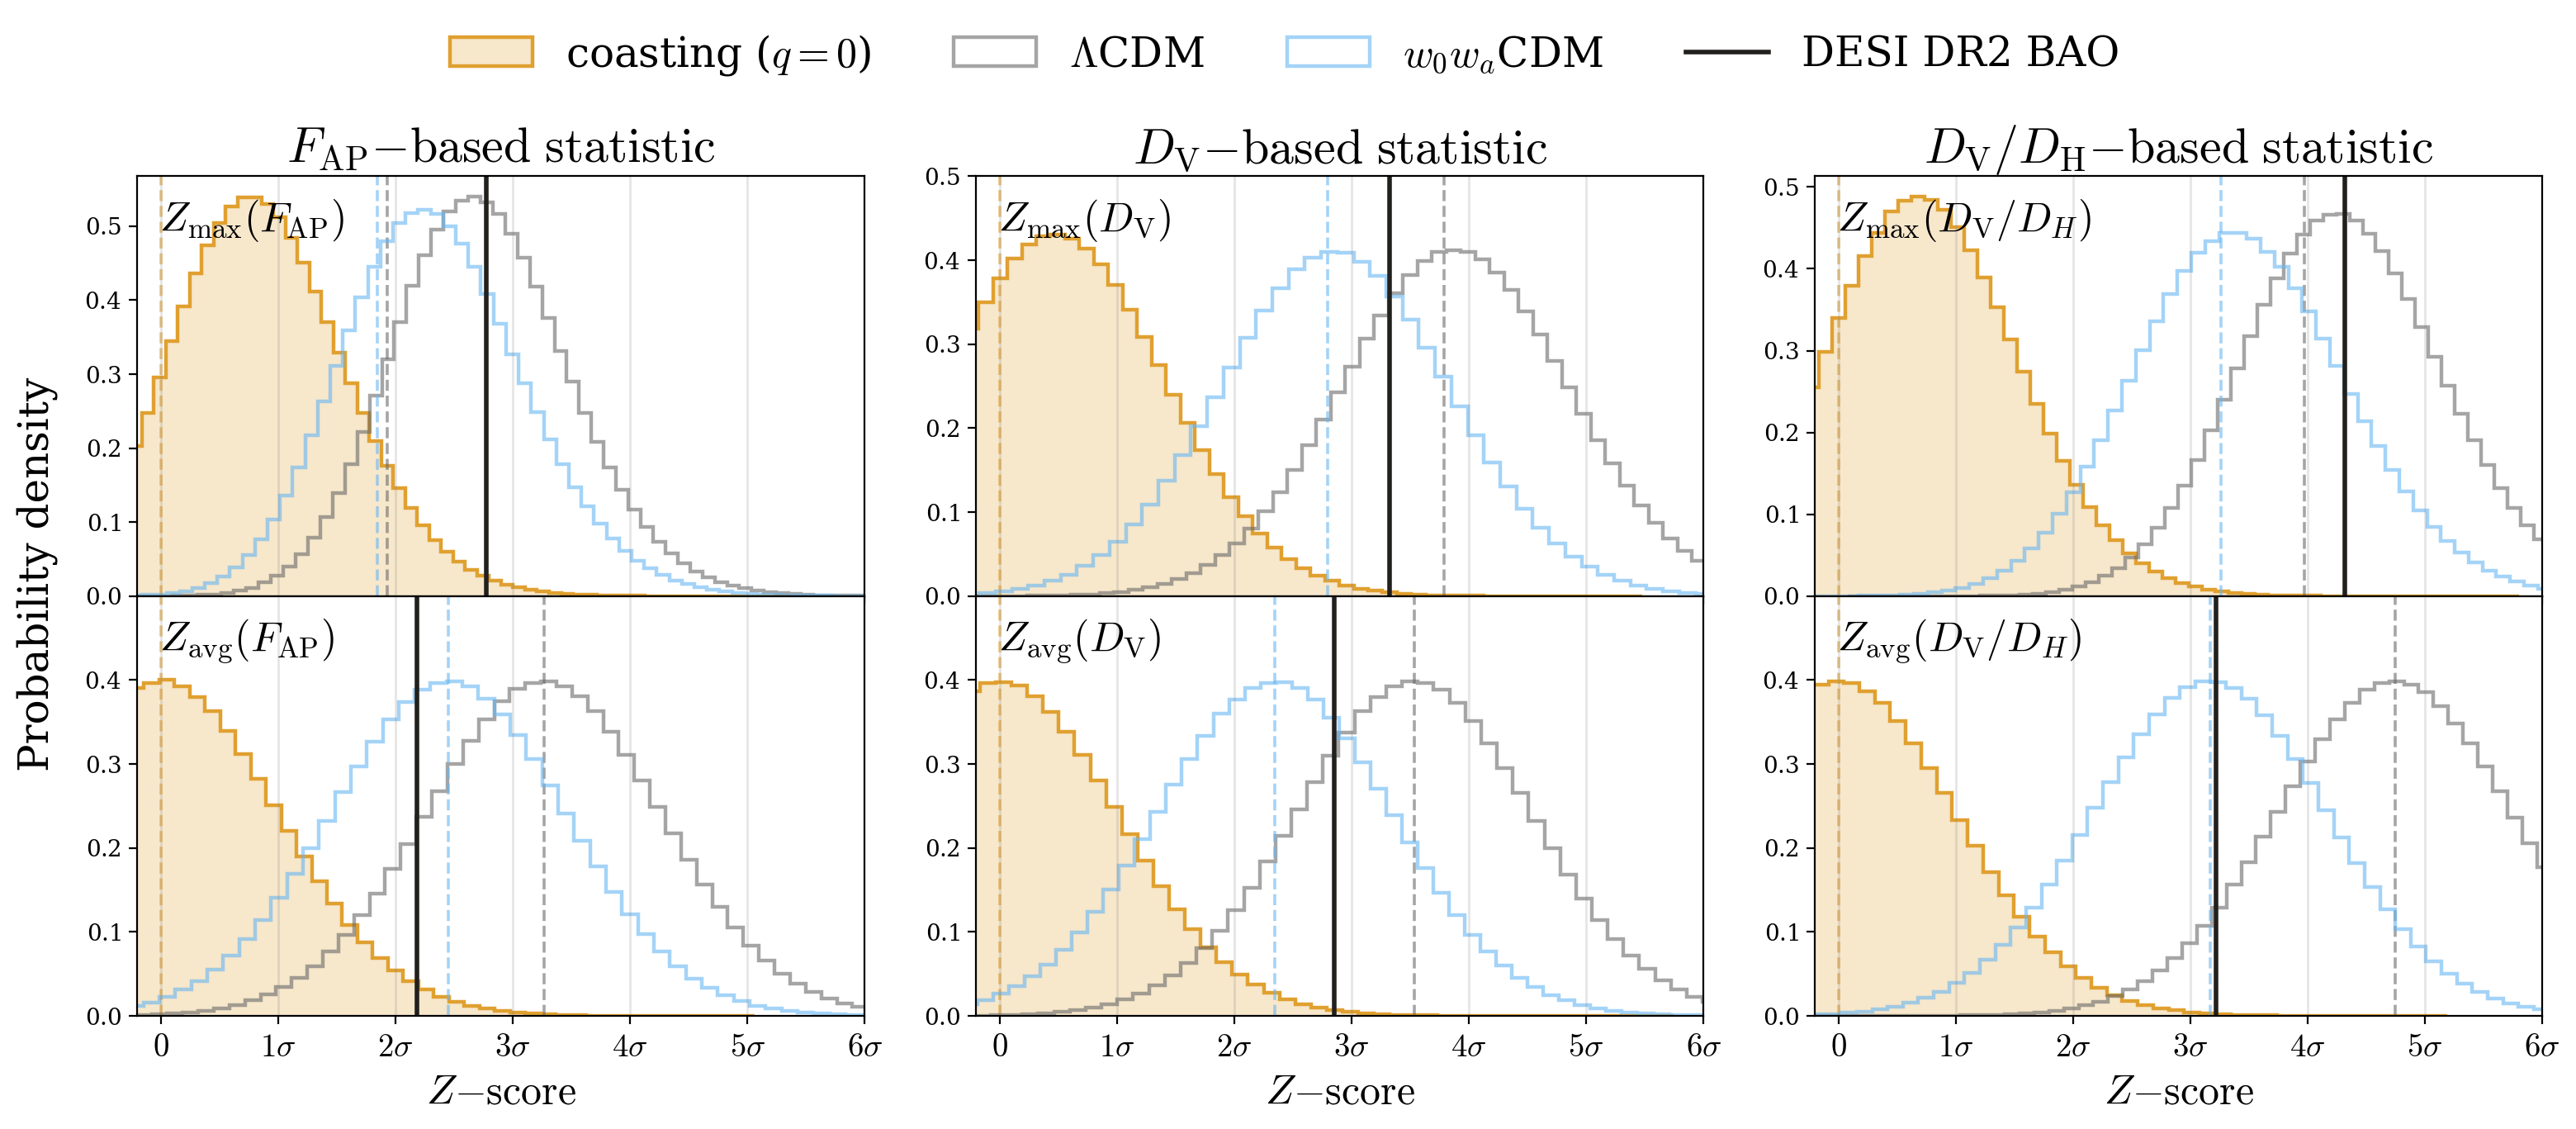

In [15]:
with plt.rc_context(cm_rc):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex="col")
    stat_symbol = {"Z_F": r"F_\mathrm{AP}", "Z_V": r"D_\mathrm{V}", "Z_VH": r"D_\mathrm{V}/D_H"}
    for col, stat in enumerate(("Z_F", "Z_V", "Z_VH")):
        for row, kind in enumerate(("max", "avg")):
            ax = axes[row, col]
            for t in TRUTHS:
                if t == "coasting": 
                    ax.hist(mocks[t][f"{stat}_{kind}_mock"], bins=80, density=True, histtype="stepfilled", color=COLORS[t], alpha=0.25, zorder=0, label=LABELS[t])
                    ax.hist(mocks[t][f"{stat}_{kind}_mock"], bins=80, density=True, histtype="step", color=COLORS[t], linewidth=1.6, label=LABELS[t])
                else:
                    ax.hist(mocks[t][f"{stat}_{kind}_mock"], bins=80, density=True, histtype="step", color=COLORS[t], linewidth=1.6, label=LABELS[t], alpha=0.6)
                ax.axvline(mocks[t][f"{stat}_{kind}_true"], color=COLORS[t], ls="--", lw=1.3, alpha=0.6)
            ax.axvline(real[f"{stat}_{kind}"], color=color_real, label=label_real, lw=2)
            # aesthetics
            ax.set_xlim(-0.2, 6) 
            for x in [0, 1, 2, 3, 4, 5, 6]: ax.axvline(x, color="gray", alpha=0.2, lw=1)
            ax.text(0.03, 0.95, rf"$Z_\mathrm{{{kind}}}({stat_symbol[stat]})$", transform=ax.transAxes, ha="left", va="top", fontsize=fontsize)
            if ax == axes[0, 0]: ax.set_title(r"$F_\mathrm{AP}\mathrm{-based\ statistic}$")
            if ax == axes[0, 1]: ax.set_title(r"$D_\mathrm{V}\mathrm{-based\ statistic}$")
            if ax == axes[0, 2]: ax.set_title(r"$D_\mathrm{V}/D_\mathrm{H}\mathrm{-based\ statistic}$")
            if ax in axes[0]:
                ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
            else:
                ax.set_xlabel(r"$Z\mathrm{-score}$")
                ax.xaxis.set_major_formatter(sigma_formatter)
                ax.tick_params(axis="x", labelsize=sigma_ticksize)
                ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4])
                ax.set_ylim(0,0.5)

    #Legend
    fig.align_ylabels(axes[:, 0])
    fig.align_ylabels(axes[:, 1])
    fig.align_ylabels(axes[:, 2])
    fig.supylabel("Probability density", fontsize=fontsize, x=0.02)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    merged = {}
    for h, l in zip(handles, labels):
        merged[l] = merged[l] + (h,) if l in merged else (h,)
    labels = list(merged)
    handles = [hs if len(hs) > 1 else hs[0] for hs in merged.values()]
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.), ncol=len(labels), frameon=False, fontsize=fontsize)
    fig.subplots_adjust(hspace=0.0)
    
plt.savefig("Fig3.pdf", format="PDF", bbox_inches="tight")


In [16]:
print(f"{'':16s}{'Z_max_true':>10s}{'<Z_max>':>10s}{'std(Z_max)':>10s}{'Z_max_true':>10s}{'<Z_max>':>10s}{'std(Z_max)':>10s}")
for stat in ['Z_F', 'Z_V', 'Z_VH']:
    print("----------------------------------------------------------------------------")
    for cosmo in mocks: print(f"{stat:6s}{cosmo:10s}{mocks[cosmo][f'{stat}_max_true']:10.2f}{np.mean(mocks[cosmo][f'{stat}_max_mock']):10.2f}{np.std(mocks[cosmo][f'{stat}_max_mock']):10.2f}{mocks[cosmo][f'{stat}_avg_true']:10.2f}{np.mean(mocks[cosmo][f'{stat}_avg_mock']):10.2f}{np.std(mocks[cosmo][f'{stat}_avg_mock']):10.2f}")
print("-----------------------------------------------------------------------------")

                Z_max_true   <Z_max>std(Z_max)Z_max_true   <Z_max>std(Z_max)
----------------------------------------------------------------------------
Z_F   coasting        0.00      0.85      0.75      0.00     -0.00      1.00
Z_F   desi_lcdm       1.93      2.74      0.75      3.27      3.27      1.00
Z_F   w0wacdm         1.84      2.33      0.77      2.45      2.45      1.00
----------------------------------------------------------------------------
Z_V   coasting        0.00      0.49      0.92      0.00      0.00      1.00
Z_V   desi_lcdm       3.79      3.89      0.96      3.53      3.53      1.00
Z_V   w0wacdm         2.79      2.86      0.97      2.35      2.35      1.00
----------------------------------------------------------------------------
Z_VH  coasting        0.00      0.73      0.82      0.00      0.00      1.00
Z_VH  desi_lcdm       3.97      4.30      0.86      4.74      4.74      1.00
Z_VH  w0wacdm         3.26      3.43      0.90      3.17      3.17      1.00

## Compute $p$-values under the coasting null hypothesis

This takes into account the look-elsewhere effect for $Z_\mathrm{max}$ ($Z_\mathrm{avg})$ is Gaussian in the measurments and doesn't need a look-elsewhere correction). We compute it in two ways:
- Numerical: The fraction of mocks under the null that lie above the measured value of S
$$p = N_{S_\mathrm{mocks}>S_\mathrm{real}}/N_\mathrm{mocks}$$
- Analytical: with $\Phi_m$ cumulative distribution function of an $m$-dimensional Gaussian with covariance $R_{ij}$
$$p = 1 - \Phi_m(Z_\mathrm{obs},\dots, Z_\mathrm{obs};\, R)$$

In [17]:
# Numerical p-value from mocks
print(f"{'':10s}{'p-value':>10s}{'sigma':>10s}")
for col, stat in enumerate(("Z_F", "Z_V", "Z_VH")):
    for row, kind in enumerate(("max", "avg")):
        null = mocks["coasting"][f"{stat}_{kind}_mock"]
        p = float(np.mean(null >= real[f"{stat}_{kind}"]))
        sigma = float(norm.ppf(1.0 - p))  # one-sided p-value -> equivalent-sigma
        real[f"{stat}_{kind}_pval"] = p
        real[f"{stat}_{kind}_sigma"] = sigma
        print(f"{stat}_{kind:6s}{100*p:9.2f} %{sigma:9.2f}")


             p-value     sigma
Z_F_max        0.84 %     2.39
Z_F_avg        1.45 %     2.18
Z_V_max        0.12 %     3.04
Z_V_avg        0.22 %     2.85
Z_VH_max        0.00 %     4.05
Z_VH_avg        0.07 %     3.21


In [18]:
# Analytic p-value (no mocks)
cov_S = {"Z_F": np.diag(sigma_SF_real ** 2), "Z_V": SIGMA_SV_COV, "Z_VH": SIGMA_VH_COV}

print(f"{'':10s}{'p (analytic)':>14s}{'sigma':>8s}{'sigma (MC)':>12s}")
for stat in ("Z_F", "Z_V", "Z_VH"):
    C = cov_S[stat][:m_zmax, :m_zmax]
    R = C / np.sqrt(np.outer(np.diag(C), np.diag(C)))
    z_obs = real[f"{stat}_max"]
    p_max = 1.0 - multivariate_normal.cdf(np.full(m_zmax, z_obs), mean=np.zeros(m_zmax), cov=R, abseps=1e-12, releps=1e-8)
    p_avg = norm.sf(real[f"{stat}_avg"])
    for kind, p in (("max", p_max), ("avg", p_avg)):
        sigma = float(norm.isf(p))  # one-sided p-value -> equivalent sigma
        real[f"{stat}_{kind}_pval_analytic"] = p
        real[f"{stat}_{kind}_sigma_analytic"] = sigma
        print(f"{stat}_{kind:6s}{p:14.2e}{sigma:8.2f}{real[f'{stat}_{kind}_sigma']:12.2f}")

            p (analytic)   sigma  sigma (MC)
Z_F_max         8.36e-03    2.39        2.39
Z_F_avg         1.44e-02    2.19        2.18
Z_V_max         1.18e-03    3.04        3.04
Z_V_avg         2.19e-03    2.85        2.85
Z_VH_max         2.41e-05    4.06        4.05
Z_VH_avg         6.46e-04    3.22        3.21


# Fig. 4: compute p-value under coasting null for all possible measurements
Survival probability of $Z_\mathrm{max}$ under the coasting null, $P(Z_\mathrm{max} \geq Z) = 1-\Phi_m(Z,\dots,Z;\,R)$, including the look-elsewhere effect over the first $m$ bins.

mock p-value: reverse-cumulative histogram = fraction of coasting mocks with Z_max >= left bin edge

In [19]:
def p_max_null(z, R):
    """P(Z_max >= z) under the coasting null, for correlation matrix R of the first m bins"""
    # absolute tolerance scaled to the tail size: ~0.1% relative accuracy on p, ~10x faster than a fixed abseps=1e-12
    return 1.0 - multivariate_normal.cdf(np.full(len(R), z), mean=np.zeros(len(R)), cov=R, abseps=1e-3 * norm.sf(z), releps=0)

real['p-value'] = {}
real['p-value']['Zgrid'] = np.linspace(0.0, 5.0, 101)
for stat, st in stat_style.items():
    C = cov_S[stat][:m_zmax, :m_zmax]
    R = C / np.sqrt(np.outer(np.diag(C), np.diag(C)))
    real['p-value'][stat] = [p_max_null(z, R) for z in real['p-value']['Zgrid']]

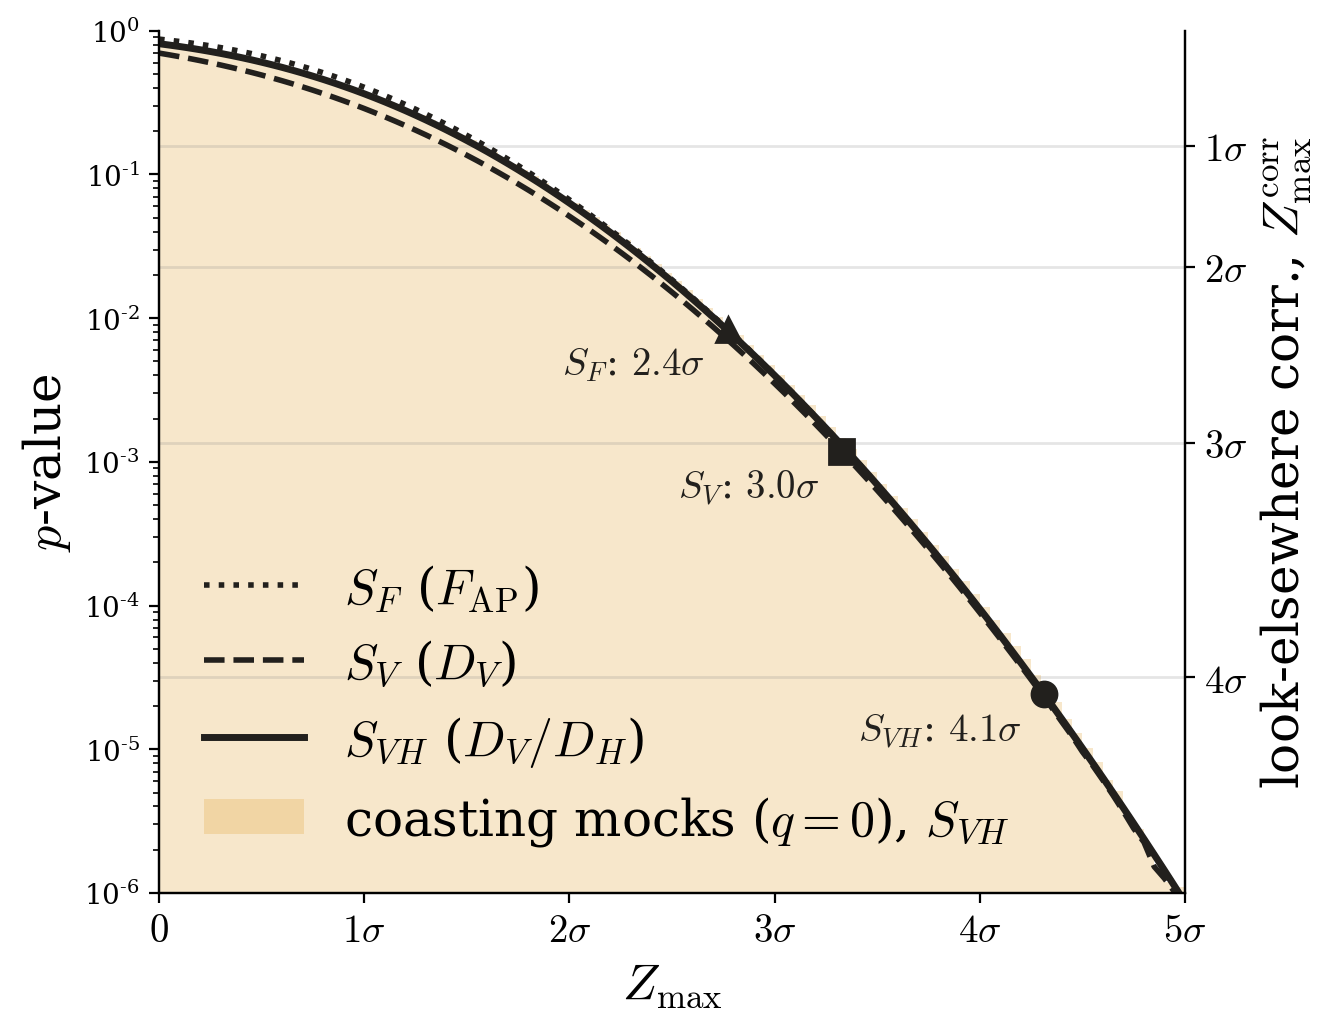

In [20]:
with plt.rc_context(cm_rc):
    fig, axp = plt.subplots(figsize=(7, 5.5))

    # p-value of Z_max under the coasting null (look-elsewhere corrected); bottom panel of Fig. 4
    zgrid = np.linspace(0.0, 5.0, 101)
    # mock p-value: reverse-cumulative histogram = fraction of coasting mocks with Z_max >= left bin edge
    axp.hist(mocks["coasting"]["Z_VH_max_mock"], bins=np.arange(-3.0, 6.0 + 1e-9, 0.05), density=True, cumulative=-1, histtype="stepfilled",
             color=COLORS["coasting"], alpha=0.25, zorder=0, label=r"coasting mocks ($q=0$), $S_{VH}$")
    for stat, st in stat_style.items():
        axp.plot(real['p-value']['Zgrid'], real['p-value'][stat], color=color_real, ls=st["ls"], lw=st["lw"], label=st["label"], zorder=3)
        axp.plot(real[f"{stat}_max"], real[f"{stat}_max_pval_analytic"], marker=st["marker"], ms=9, color=color_real, ls="", zorder=4)
        # look-elsewhere corrected evidence for acceleration next to each marker
        axp.annotate(rf"{st['label'].split(' (')[0]}: ${real[f'{stat}_max_sigma_analytic']:.1f}\sigma$",
                      (real[f"{stat}_max"], real[f"{stat}_max_pval_analytic"]), xytext=(-8, -6), textcoords="offset points",
                      ha="right", va="top", fontsize=14, color=color_real, zorder=5)

    axp.set_yscale("log")
    axp.set_xlim(0.0, 5.0)
    axp.set_ylim(1e-6, 1.0)
    axp.set_xlabel(r"$Z_\mathrm{max}$", fontsize=fontsize)
    axp.xaxis.set_major_formatter(sigma_formatter)
    axp.tick_params(axis="x", labelsize=sigma_ticksize)
    axp.set_ylabel(r"$p$-value", fontsize=fontsize)
    # lines first, coasting-mock histogram last
    h, l = axp.get_legend_handles_labels()
    axp.legend(h[1:] + h[:1], l[1:] + l[:1], loc="lower left", frameon=False, fontsize=fontsize)

    # equivalent one-sided significance on the right axis
    axs = axp.twinx()
    axs.set_yscale("log")
    axs.set_ylim(axp.get_ylim())
    axs.set_yticks(norm.sf(np.arange(1, 5)))
    axs.set_yticklabels([rf"${k}\sigma$" for k in range(1, 5)], fontsize=sigma_ticksize)
    axs.minorticks_off()
    axs.set_ylabel(r"look-elsewhere corr., $Z_\mathrm{max}^\mathrm{corr}$", fontsize=fontsize)
    for k in range(1, 5): axp.axhline(norm.sf(k), color="gray", alpha=0.2, lw=1)

    axp.spines["top"].set_visible(False)
    axs.spines["top"].set_visible(False)
    fig.tight_layout()

plt.savefig("Fig4.pdf", format="PDF", bbox_inches="tight")


## Summary plot for talks

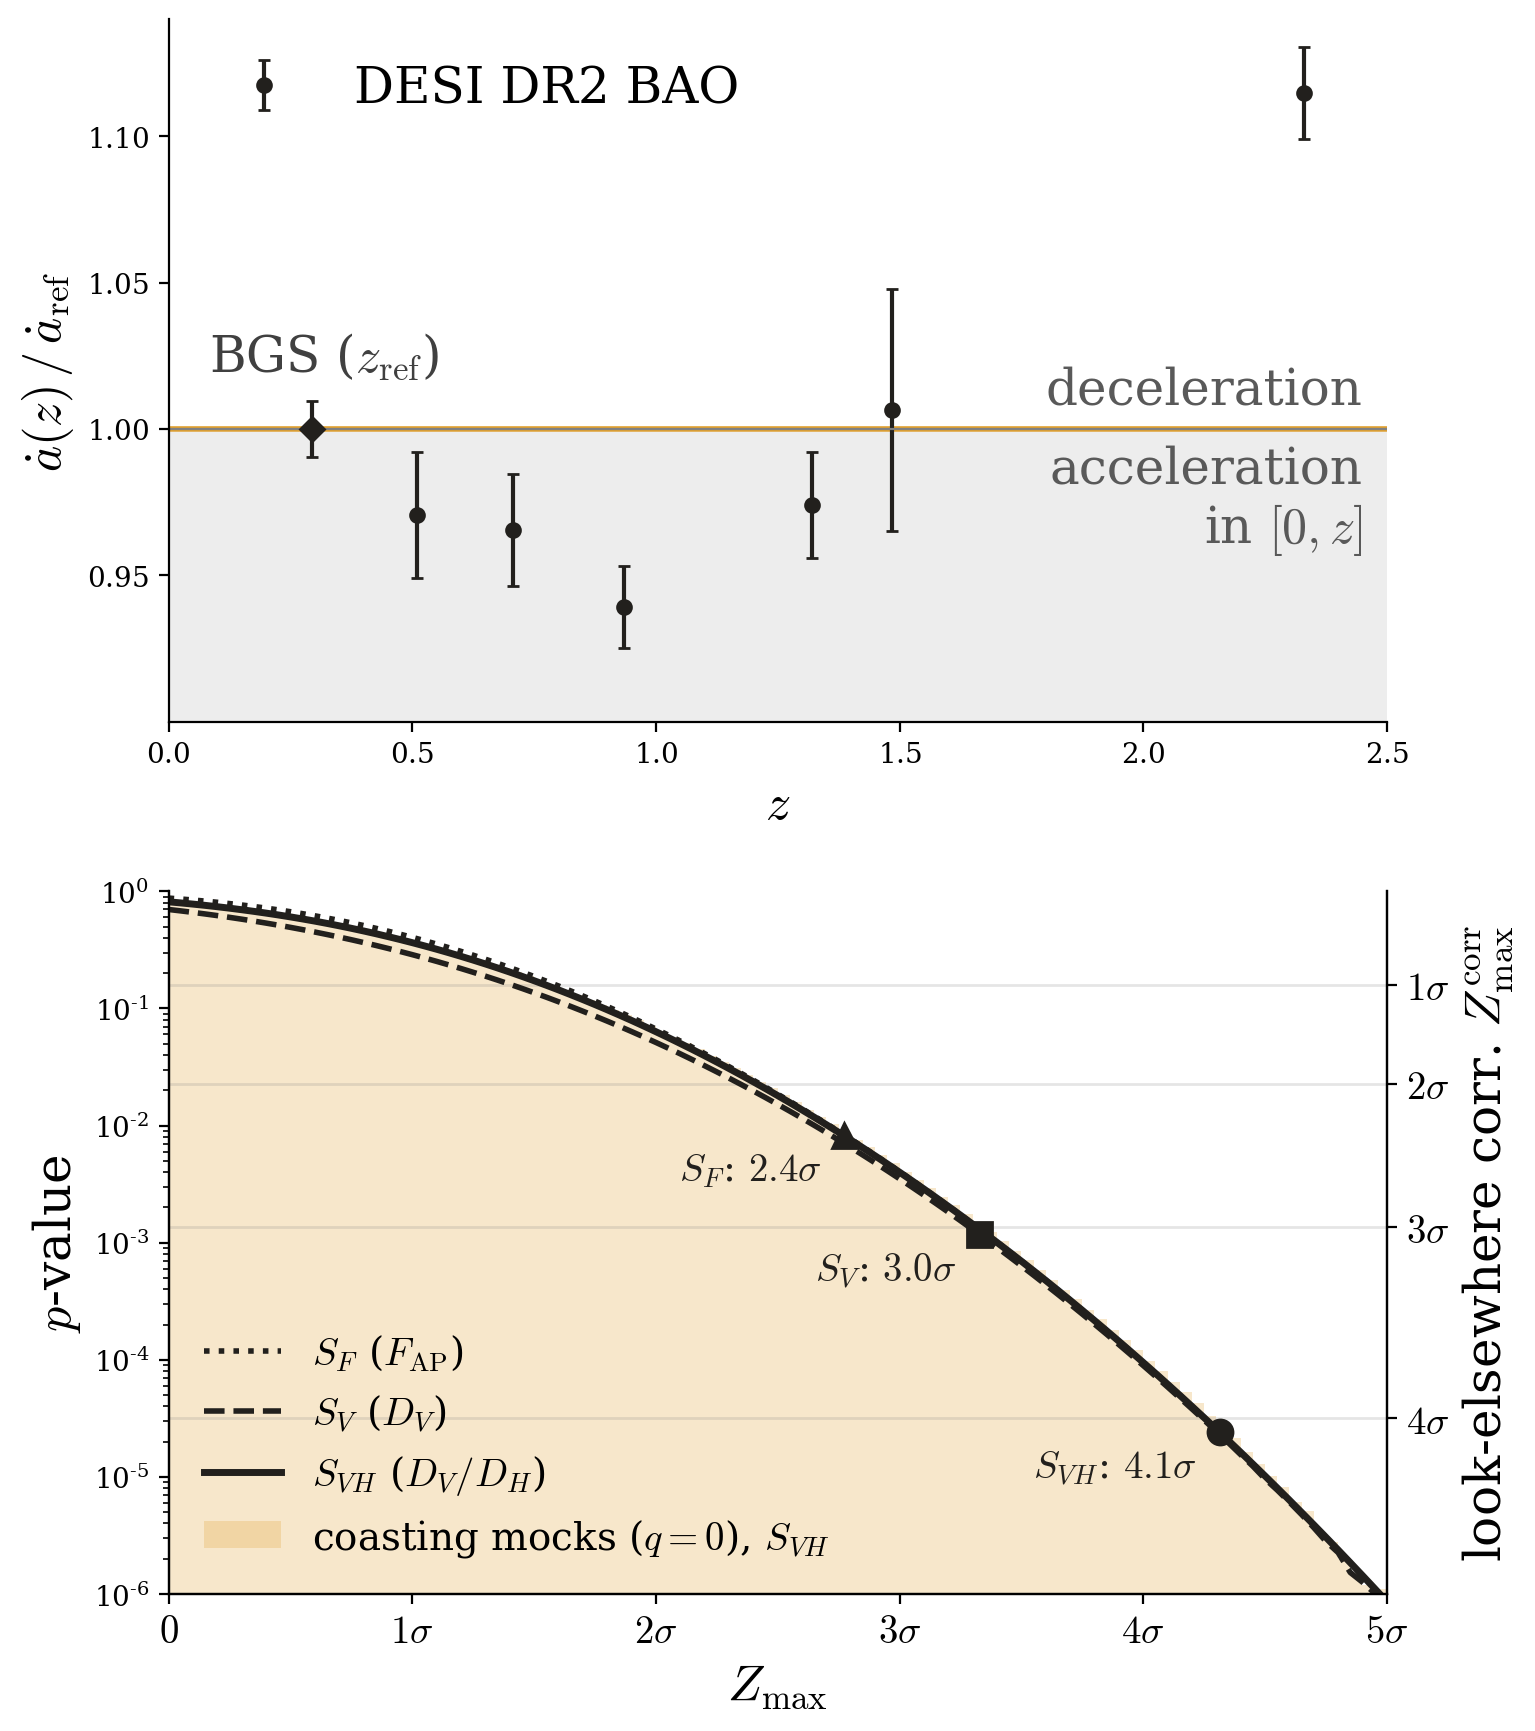

In [21]:
with plt.rc_context(cm_rc):
    fig, (ax, axp) = plt.subplots(2, 1, figsize=(8, 9))

    # top: expansion speed relative to the coasting boundary
    zfine_vh = np.linspace(0, 2.5, 2000)
    c_VH = (1.0 + Z) * g_coasting(Z_BGS)
    t = "coasting"
    dv_ref = mocks[t]["dv_fn"](Z_BGS)
    ax.plot(zfine_vh, dv_ref / ((1.0 + zfine_vh) * g_coasting(Z_BGS) * mocks[t]["dh_fn"](zfine_vh)), color=COLORS[t], lw=2)

    y_VH_real = DV_BGS / (c_VH * DH)
    yerr_VH_real = sigma_SVH_real / (c_VH * DH)
    ax.errorbar(Z, y_VH_real, yerr=yerr_VH_real, marker="o", ms=5, ls="", color=color_real, lw=1.5, capsize=2, label=label_real)
    ax.errorbar([Z_BGS], [1.0], yerr=[DV_BGS_ERR / DV_BGS], marker="D", ms=6, ls="", color=color_real, capsize=2)
    ax.annotate(r"BGS ($z_\mathrm{ref}$)", (Z_BGS, 1.0), xytext=(0.32, 1.02), ha="center", fontsize=fontsize, color="0.25")

    # acceleration side of the coasting boundary
    ax.axhspan(0.0, 1.0, color="0.93", zorder=0)
    ax.axhline(1.0, color="grey", lw=0.8)
    ax.text(2.45, 0.995, "acceleration\nin $[0,z]$", ha="right", va="top", fontsize=fontsize, color="0.35")
    ax.text(2.45, 1.005, "deceleration", ha="right", va="bottom", fontsize=fontsize, color="0.35")

    ax.set_xlabel(r"$z$", fontsize=fontsize)
    ax.set_ylabel(r"$\dot a(z)\,/\,\dot a_{\rm ref}$", fontsize=fontsize)
    ax.set_ylim(0.90, 1.14)
    ax.set_xlim(0.0, 2.5)
    ax.set_yticks([0.95, 1.0, 1.05, 1.1])
    ax.legend(loc="upper left", frameon=False, fontsize=fontsize)

    # bottom: p-value of Z_max under the coasting null (look-elsewhere corrected)
    #zgrid = np.linspace(0.0, 5.0, 101)
    # 
    axp.hist(mocks["coasting"]["Z_VH_max_mock"], bins=np.arange(-3.0, 6.0 + 1e-9, 0.05), density=True, cumulative=-1, histtype="stepfilled",
             color=COLORS["coasting"], alpha=0.25, zorder=0, label=r"coasting mocks ($q=0$), $S_{VH}$")
    for stat, st in stat_style.items():
        axp.plot(real['p-value']['Zgrid'], real['p-value'][stat], color=color_real, ls=st["ls"], lw=st["lw"], label=st["label"], zorder=3)
        axp.plot(real[f"{stat}_max"], real[f"{stat}_max_pval_analytic"], marker=st["marker"], ms=9, color=color_real, ls="", zorder=4)
        # look-elsewhere corrected evidence for acceleration next to each marker
        axp.annotate(rf"{st['label'].split(' (')[0]}: ${real[f'{stat}_max_sigma_analytic']:.1f}\sigma$",
                      (real[f"{stat}_max"], real[f"{stat}_max_pval_analytic"]), xytext=(-8, -6), textcoords="offset points",
                      ha="right", va="top", fontsize=14, color=color_real, zorder=5)

    axp.set_yscale("log")
    axp.set_xlim(0.0, 5.0)
    axp.set_ylim(1e-6, 1.0)
    axp.set_xlabel(r"$Z_\mathrm{max}$", fontsize=fontsize)
    axp.xaxis.set_major_formatter(sigma_formatter)
    axp.tick_params(axis="x", labelsize=sigma_ticksize)
    axp.set_ylabel(r"$p$-value", fontsize=fontsize)
    # lines first, coasting-mock histogram last
    h, l = axp.get_legend_handles_labels()
    axp.legend(h[1:] + h[:1], l[1:] + l[:1], loc="lower left", frameon=False, fontsize=14)

    # equivalent one-sided significance on the right axis
    axs = axp.twinx()
    axs.set_yscale("log")
    axs.set_ylim(axp.get_ylim())
    axs.set_yticks(norm.sf(np.arange(1, 5)))
    axs.set_yticklabels([rf"${k}\sigma$" for k in range(1, 5)], fontsize=sigma_ticksize)
    axs.minorticks_off()
    axs.set_ylabel(r"look-elsewhere corr. $Z_\mathrm{max}^\mathrm{corr}$", fontsize=fontsize)
    for k in range(1, 5): axp.axhline(norm.sf(k), color="gray", alpha=0.2, lw=1)

    for a in (ax, axp):
        a.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    axs.spines["top"].set_visible(False)
    fig.tight_layout()


##  $T$-statistic

This is not shown in the paper; just for diagnostic purposes. For each truth and each statistic:
$$T^i=Z^i_{\rm mock}-Z_{\rm true}.$$


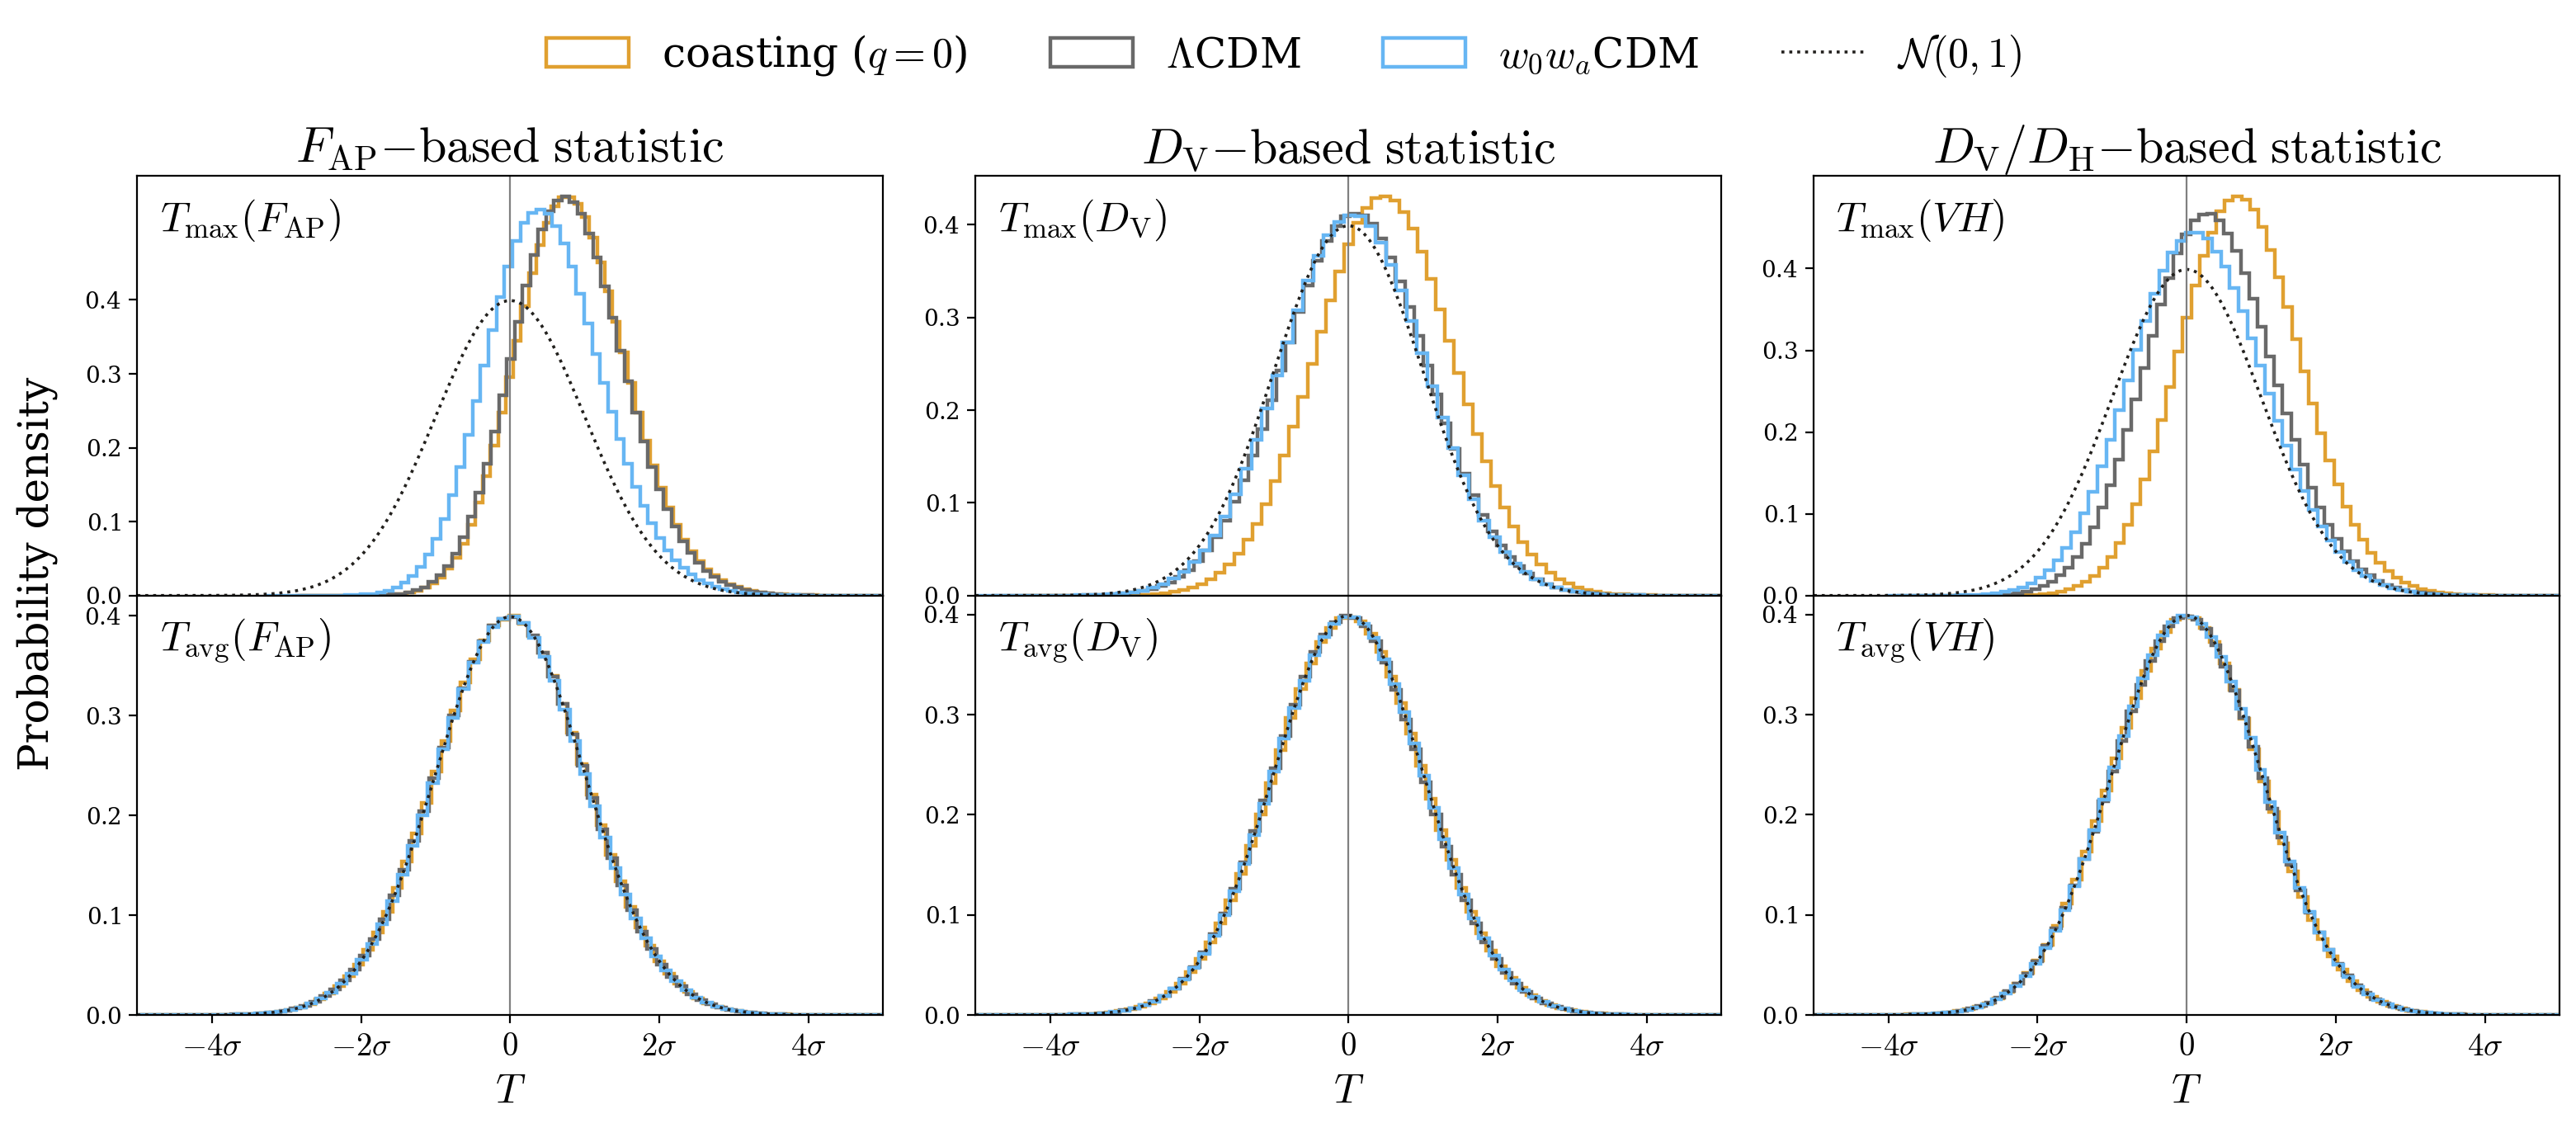

In [22]:
with plt.rc_context(cm_rc):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex="col")
    stat_symbol = {"Z_F": r"F_\mathrm{AP}", "Z_V": r"D_\mathrm{V}", "Z_VH": r"VH"}
    xg = np.linspace(-5, 5, 300)
    for col, stat in enumerate(("Z_F", "Z_V", "Z_VH")):
        for row, kind in enumerate(("max", "avg")):
            ax = axes[row, col]
            for t in TRUTHS:
                # T^i = sigma^i_mock - sigma_true (Eq. 16, sigma_self fixed)
                T_mock = mocks[t][f"{stat}_{kind}_mock"] - mocks[t][f"{stat}_{kind}_true"]
                ax.hist(T_mock, bins=80, density=True, histtype="step", color=COLORS[t], linewidth=1.6, label=LABELS[t])
            ax.plot(xg, norm.pdf(xg), ls=":", lw=1.3, color=color_real, label=r"$\mathcal{N}(0,1)$")
            ax.axvline(0, color="grey", lw=0.8)
            # aesthetics
            ax.set_xlim(-5, 5)
            ax.text(0.03, 0.95, rf"$T_\mathrm{{{kind}}}({stat_symbol[stat]})$", transform=ax.transAxes, ha="left", va="top", fontsize=fontsize)
            if ax == axes[0, 0]: ax.set_title(r"$F_\mathrm{AP}\mathrm{-based\ statistic}$")
            if ax == axes[0, 1]: ax.set_title(r"$D_\mathrm{V}\mathrm{-based\ statistic}$")
            if ax == axes[0, 2]: ax.set_title(r"$D_\mathrm{V}/D_\mathrm{H}\mathrm{-based\ statistic}$")
            if ax in axes[0]:
                ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4])
            else:
                ax.set_xlabel(r"$T$")
                ax.xaxis.set_major_formatter(sigma_formatter)
                ax.tick_params(axis="x", labelsize=sigma_ticksize)
                ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4])

    #Legend
    fig.align_ylabels(axes[:, 0])
    fig.align_ylabels(axes[:, 1])
    fig.align_ylabels(axes[:, 2])
    fig.supylabel("Probability density", fontsize=fontsize, x=0.02)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
    fig.subplots_adjust(hspace=0.0)  # no v-space between rows
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.), ncol=len(labels), frameon=False, fontsize=fontsize)
    fig.subplots_adjust(hspace=0.0)

#plt.savefig("Fig_T.pdf", format="PDF", bbox_inches="tight")


# Redshift distribution
Searched over all tracers, to show where the redshift that maximizes the signal sits.

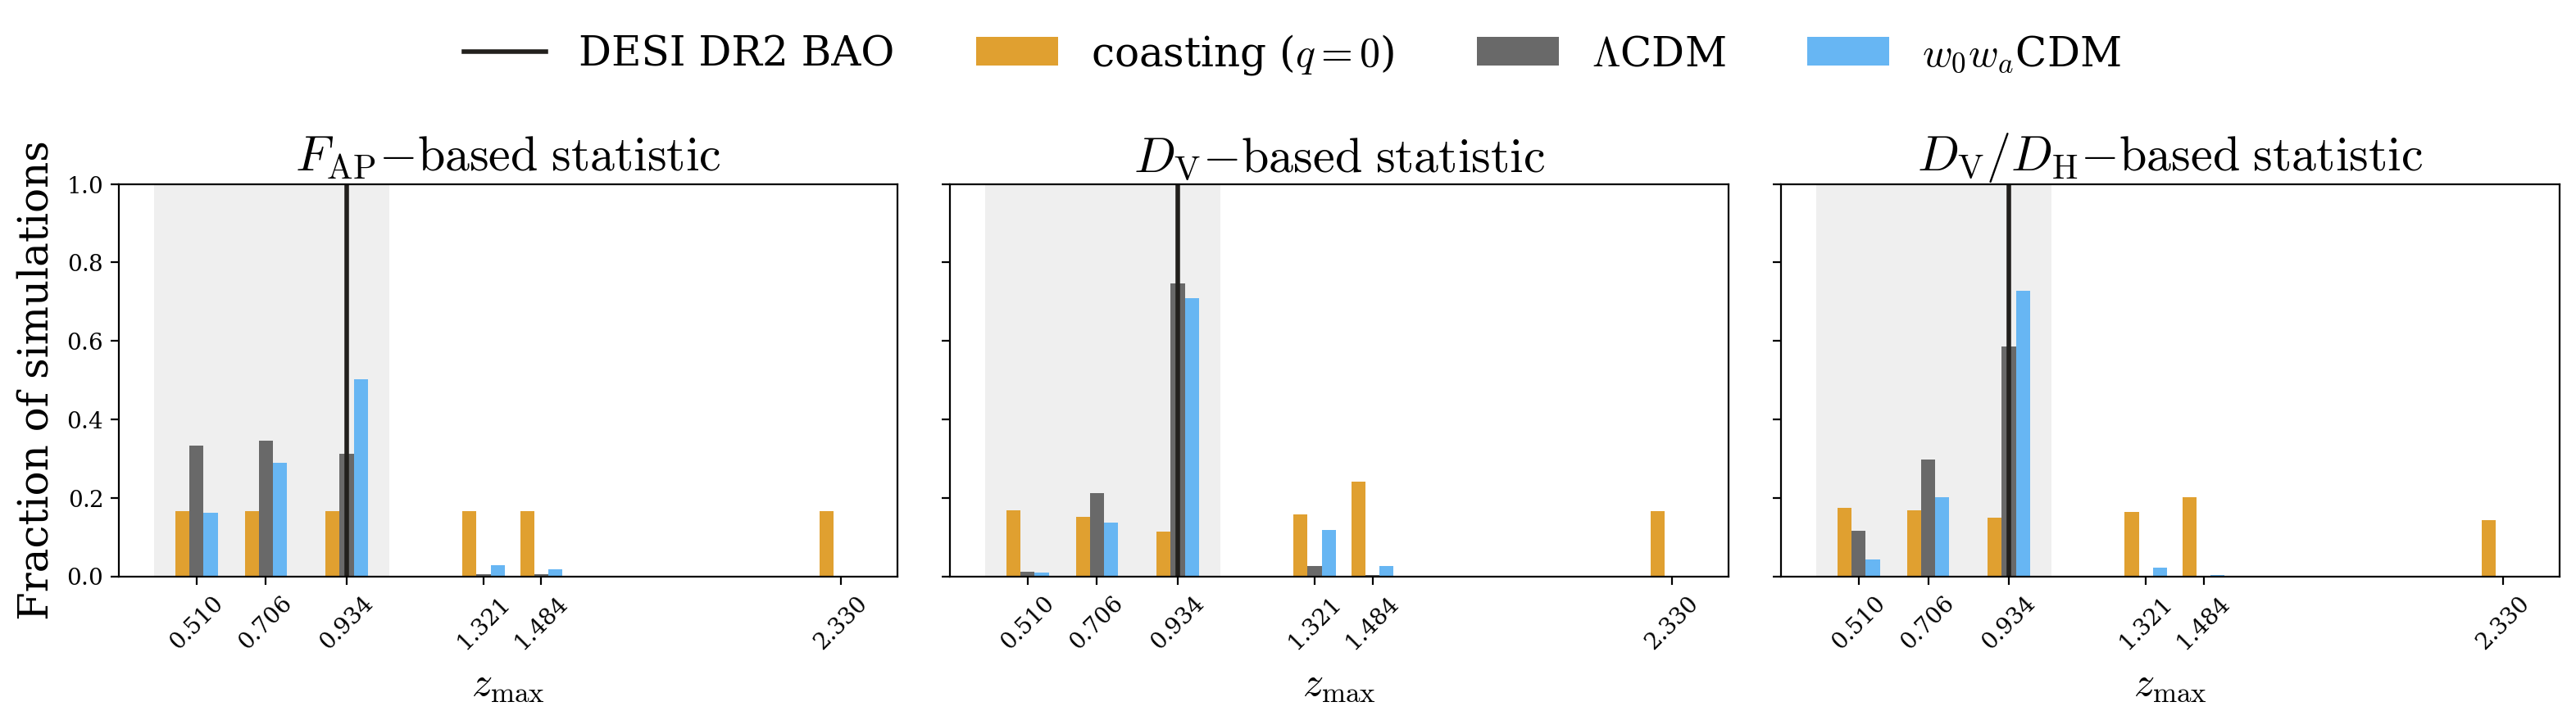

In [23]:
m_argmax = len(Z)
stat_title = {"Z_F": r"$F_\mathrm{AP}\mathrm{-based\ statistic}$",
              "Z_V": r"$D_\mathrm{V}\mathrm{-based\ statistic}$",
              "Z_VH": r"$D_\mathrm{V}/D_\mathrm{H}\mathrm{-based\ statistic}$"}
real_Z = {"Z_F": Z_F_real, "Z_V": Z_V_real, "Z_VH": Z_VH_real}
width = 0.04
with plt.rc_context(cm_rc):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
    for ax, stat in zip(axes, ("Z_F", "Z_V", "Z_VH")):
        for k, t in enumerate(TRUTHS):
            i_max = np.argmax(mocks[t][f"{stat}_mock"][:, :m_argmax], axis=1)
            frac = np.bincount(i_max, minlength=m_argmax) / len(i_max)
            ax.bar(Z[:m_argmax] + (k - 1) * width, frac, width=width, color=COLORS[t], label=LABELS[t])
        z_real = Z[np.argmax(real_Z[stat][:m_argmax])]
        ax.axvline(z_real, color=color_real, lw=2, label=label_real)
        ax.axvspan(Z[0] - 3 * width, Z[m_zmax - 1] + 3 * width, color="gray", alpha=0.12, lw=0, zorder=0)
        ax.set_xticks(Z[:m_argmax])
        ax.set_xticklabels([f"{z:.3f}" for z in Z[:m_argmax]], rotation=45)
        ax.set_xlabel(r"$z_\mathrm{max}$")
        ax.set_title(stat_title[stat])
        ax.set_ylim(0, 1)
    axes[0].set_ylabel("Fraction of simulations")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.88))
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.), ncol=len(labels), frameon=False, fontsize=fontsize)


plt.savefig("Fig_zargmax.pdf", format="PDF", bbox_inches="tight")